In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from geopy.distance import geodesic

In [7]:
data = pd.read_excel("anomalies_corrected_data.xlsx", sheet_name="Data")
data_dist = data.copy()
print(data["step"])

0            1
1            2
2            3
3            4
4            5
         ...  
15870    15871
15871    15872
15872    15873
15873    15874
15874    15875
Name: step, Length: 15875, dtype: int64


In [22]:
data["distances"] = [geodesic(
        (data["latitude"].iloc[i], data["longitude"].iloc[i]),
        (data["latitude"].iloc[i+1], data["longitude"].iloc[i+1])
        ).km for i in range(len(data)-1)] + [None] #plus None because the comparision shirnks the data into len(data)-1

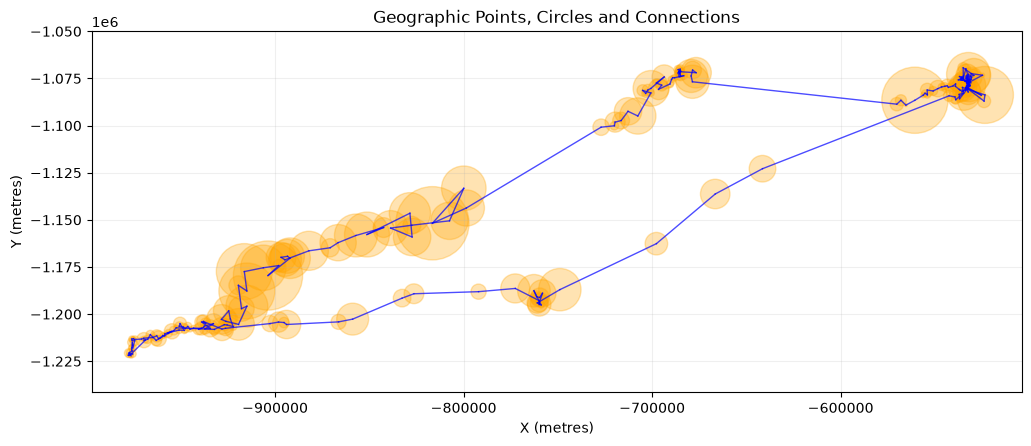

In [ ]:

from pyproj import Transformer
import matplotlib.pyplot as plt
import random

sub_data = data.drop_duplicates(subset=["latitude", "longitude"]).head(600)

latitude, longitude, outer_radius = sub_data["latitude"], sub_data["longitude"], sub_data["outer_radius"]

transformer = Transformer.from_crs("EPSG:4326", "EPSG:5514", always_xy=True) #input, output

x_vals, y_vals = transformer.transform(longitude, latitude)

fig, ax = plt.subplots(figsize=(12, 10))

for i in range(len(sub_data)-1):

    x, y, r = x_vals[i], y_vals[i], outer_radius.iloc[i]

    x_next, y_next, r_next = x_vals[i+1], y_vals[i+1], outer_radius.iloc[i+1]

    circle = plt.Circle(
        (x, y),
        radius=r,
        facecolor="orange",
        alpha=0.3,
        edgecolor="orange"
    )

    ax.add_patch(circle)

    ax.plot(
        [x, x_next],
        [y, y_next],
        color="blue",
        linewidth=1,
        alpha=0.7,
        zorder=2
    )

max_radius = outer_radius.max()

ax.set_xlim(min(x_vals) - max_radius, max(x_vals) + max_radius) #sets the x-axis value range
ax.set_ylim(min(y_vals) - max_radius, max(y_vals) + max_radius) #sets the y-axis value range

ax.set_aspect("equal")
ax.set_xlabel("X (metres)")
ax.set_ylabel("Y (metres)")
ax.set_title("Geographic Points, Circles and Connections")
ax.grid(alpha=0.2)

plt.show()


In [57]:
#drop the last line - contains None
data = data[:-1].copy()

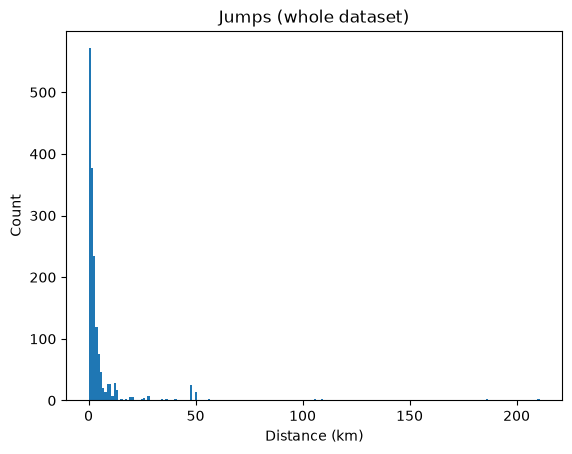

10.181311374627557


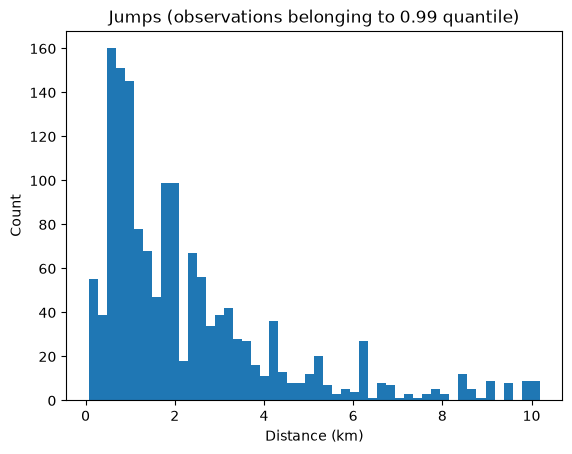

In [52]:
sub_data = data[data["distances"] != 0]
plt.hist(sub_data["distances"], bins=200)
plt.xlabel("Distance (km)")
plt.ylabel("Count")
plt.title("Jumps (whole dataset)")
plt.show()

quantile_value = data["distances"].quantile(0.99)
print(quantile_value)

sub_data = data[(data["distances"] != 0) & (data["distances"] <= quantile_value)]
plt.hist(sub_data["distances"], bins=50)
plt.xlabel("Distance (km)")
plt.ylabel("Count")
plt.title("Jumps (observations belonging to 0.99 quantile)")
plt.show()

Shows that 99% percent of data points are in the range from 0-10.18 km